In [143]:
import time
import pandas as pd
from transformers import pipeline
from google.colab import files


In [5]:
files.upload()

Saving restaurant_reviews_100_huggingface.csv to restaurant_reviews_100_huggingface.csv


{'restaurant_reviews_100_huggingface.csv': b'\xef\xbb\xbfreview_id,review,liked,sentiment,source_dataset,source_url,label_definition,source_note\r\n1,Wow... Loved this place.,1,Positive,KarthikaRajagopal/Restaurant_Reviews.tsv,https://huggingface.co/datasets/KarthikaRajagopal/Restaurant_Reviews.tsv,Original dataset label: Liked=1 means Positive; Liked=0 means Negative,Review text and label transcribed from the public Hugging Face dataset viewer preview\r\n2,Crust is not good.,0,Negative,KarthikaRajagopal/Restaurant_Reviews.tsv,https://huggingface.co/datasets/KarthikaRajagopal/Restaurant_Reviews.tsv,Original dataset label: Liked=1 means Positive; Liked=0 means Negative,Review text and label transcribed from the public Hugging Face dataset viewer preview\r\n3,Not tasty and the texture was just nasty.,0,Negative,KarthikaRajagopal/Restaurant_Reviews.tsv,https://huggingface.co/datasets/KarthikaRajagopal/Restaurant_Reviews.tsv,Original dataset label: Liked=1 means Positive; Liked=0 means Neg

### read the data

In [144]:
sent = pd.read_csv("restaurant_reviews_100_huggingface.csv")

In [145]:
print(sent.shape)
print(sent["sentiment"].value_counts())

(100, 8)
sentiment
Positive    53
Negative    47
Name: count, dtype: int64


In [146]:
print(sent.columns.tolist())
print(sent[["review", "sentiment"]].head())


['review_id', 'review', 'liked', 'sentiment', 'source_dataset', 'source_url', 'label_definition', 'source_note']
                                              review sentiment
0                           Wow... Loved this place.  Positive
1                                 Crust is not good.  Negative
2          Not tasty and the texture was just nasty.  Negative
3  Stopped by during the late May bank holiday of...  Positive
4  The selection on the menu was great and so wer...  Positive


In [147]:
from transformers import pipeline

pipe = pipeline("text-classification", model="karimbkh/BERT_fineTuned_Sentiment_Classification_Yelp")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [148]:
print(pipe.model.config.id2label)

{0: 'LABEL_0', 1: 'LABEL_1'}


In [149]:
pipe("The food was delicious and the service was excellent.")

[{'label': 'LABEL_1', 'score': 0.9940404295921326}]

In [150]:
pipe("The food was terrible and the service was very slow.")

[{'label': 'LABEL_0', 'score': 0.9894009232521057}]

In [151]:
print(pipe("The food was amazing but the service was awful."))
print(pipe("Okay."))

[{'label': 'LABEL_0', 'score': 0.6242429614067078}]
[{'label': 'LABEL_1', 'score': 0.5725907683372498}]


In [153]:
import time

label_map= {"LABEL_0": "NEGATIVE", "LABEL_1": "POSITIVE"}
reviews= sent["review"].astype(str).tolist()
outputs=[]
start=time.time()


for review in reviews:
    result=pipe(review)[0]
    outputs.append(result)


elapsed=time.time()- start
print("Total time:", round(elapsed, 2), "seconds")

out_df=pd.DataFrame(outputs)
sent["prediction"]=out_df["label"].map(label_map)
sent["score"]=out_df["score"]

Total time: 23.81 seconds


In [154]:
sent[["review", "sentiment", "prediction"]].head(10)

,review,sentiment,prediction
0,Wow... Loved this place.,Positive,POSITIVE
1,Crust is not good.,Negative,NEGATIVE
2,Not tasty and the texture was just nasty.,Negative,NEGATIVE
3,Stopped by during the late May bank holiday of...,Positive,POSITIVE
4,The selection on the menu was great and so wer...,Positive,POSITIVE
5,Now I am getting angry and I want my damn pho.,Negative,NEGATIVE
6,Honeslty it didn't taste THAT fresh.),Negative,NEGATIVE
7,The potatoes were like rubber and you could te...,Negative,NEGATIVE
8,The fries were great too.,Positive,POSITIVE
9,A great touch.,Positive,POSITIVE


In [156]:
sent["true_label"]=sent["sentiment"].str.upper()

In [211]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_true=sent["true_label"]
y_pred=sent["prediction"]
print("Accuracy:", accuracy_score(y_true, y_pred))
print(classification_report(y_true, y_pred, digits=3))

Accuracy: 0.93
              precision    recall  f1-score   support

    NEGATIVE      0.955     0.894     0.923        47
    POSITIVE      0.911     0.962     0.936        53

    accuracy                          0.930       100
   macro avg      0.933     0.928     0.929       100
weighted avg      0.931     0.930     0.930       100



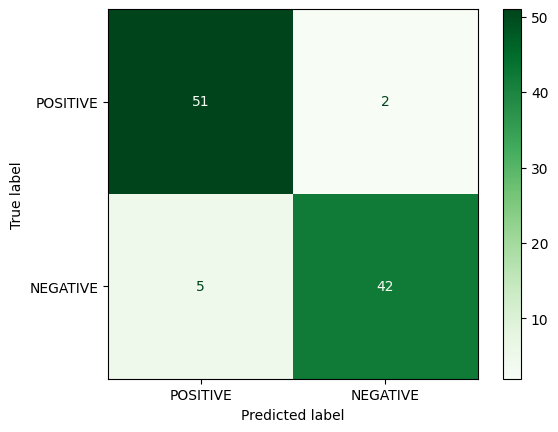

In [158]:
cm=confusion_matrix(y_true, y_pred, labels=["POSITIVE","NEGATIVE"])
ConfusionMatrixDisplay(cm, display_labels=["POSITIVE", "NEGATIVE"]).plot(cmap="Greens")
plt.show()

In [159]:
## I choose Accuracy, Precision, Recall, F1 score, and the Confusion Matrix because my task
# is binary sentiment classification with a nearly balanced dataset (53 positive, 47 negative).
#Accuracy gives the overall correctness, while Precision, Recall,
#and F1 show whether the model is biased toward one class. The confusion matrix shows which type of mistake the model
# makes. I also measured inference time to judge practicality.
# I did not use human evaluation because the model outputs a label, not generated text.

In [160]:
# positive and negative togather
pipe("It was fine, I guess")
# label 1 = positive

[{'label': 'LABEL_1', 'score': 0.5093976855278015}]

In [161]:
# Error analysis
errors=sent[sent["true_label"] != sent["prediction"]].copy()
errors=errors.sort_values("score", ascending=False)

print(len(errors),"errors out of", len(sent))
errors[["review", "true_label", "prediction", "score"]]

7 errors out of 100


,review,true_label,prediction,score
33,seems like a good quick place to grab a bite o...,NEGATIVE,POSITIVE,0.980002
56,The Heart Attack Grill in downtown Vegas is an...,NEGATIVE,POSITIVE,0.967598
79,There is so much good food in Vegas that I fee...,NEGATIVE,POSITIVE,0.801938
28,Took an hour to get our food only 4 tables in ...,NEGATIVE,POSITIVE,0.779701
51,He came running after us when he realized my h...,POSITIVE,NEGATIVE,0.751392
95,Kind of hard to mess up a steak but they did.,NEGATIVE,POSITIVE,0.718550
32,I found this place by accident and I could not...,POSITIVE,NEGATIVE,0.619703


In [162]:
#The review starts with positive words (“good quick place”) and ends with a negative recommendation.
# I think the model was influenced by the positive opening and missed the final words

In [163]:
model2=pipeline("text-classification", model="distilbert/distilbert-base-uncased-finetuned-sst-2-english")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [164]:
print(model2.model.config.id2label)

{0: 'NEGATIVE', 1: 'POSITIVE'}


In [165]:
print(model2("The food was delicious and the service was excellent."))
print(model2("The food was terrible and the service was very slow."))
print(model2("The food was amazing but the service was awful."))
print(model2("Okay."))

[{'label': 'POSITIVE', 'score': 0.9998767375946045}]
[{'label': 'NEGATIVE', 'score': 0.9998028874397278}]
[{'label': 'NEGATIVE', 'score': 0.9941845536231995}]
[{'label': 'POSITIVE', 'score': 0.9997517466545105}]


In [167]:
# same steps for model 2
reviews=sent["review"].astype(str).tolist()
outputs2=[]
start=time.time()


for review in reviews:
    result= model2(review)[0]
    outputs2.append(result)


elapsed2=time.time()-start
print("Total time:", round(elapsed2, 2), "seconds")

out_df2=pd.DataFrame(outputs2)
sent["prediction2"]= out_df2["label"]
sent["score2"]= out_df2["score"]

Total time: 13.11 seconds


In [168]:
sent[["review","prediction2","score2", "true_label"]].head(10)

,review,prediction2,score2,true_label
0,Wow... Loved this place.,POSITIVE,0.999880,POSITIVE
1,Crust is not good.,NEGATIVE,0.999769,NEGATIVE
2,Not tasty and the texture was just nasty.,NEGATIVE,0.999628,NEGATIVE
3,Stopped by during the late May bank holiday of...,POSITIVE,0.999530,POSITIVE
4,The selection on the menu was great and so wer...,POSITIVE,0.999609,POSITIVE
5,Now I am getting angry and I want my damn pho.,NEGATIVE,0.992296,NEGATIVE
6,Honeslty it didn't taste THAT fresh.),NEGATIVE,0.990978,NEGATIVE
7,The potatoes were like rubber and you could te...,NEGATIVE,0.902415,NEGATIVE
8,The fries were great too.,POSITIVE,0.999723,POSITIVE
9,A great touch.,POSITIVE,0.999884,POSITIVE


In [169]:
#evaluation:

In [170]:
y_pred2=sent["prediction2"]
print("Accuracy:", accuracy_score(y_true, y_pred2))
print(classification_report(y_true, y_pred2, digits=3))

Accuracy: 0.92
              precision    recall  f1-score   support

    NEGATIVE      0.882     0.957     0.918        47
    POSITIVE      0.959     0.887     0.922        53

    accuracy                          0.920       100
   macro avg      0.921     0.922     0.920       100
weighted avg      0.923     0.920     0.920       100



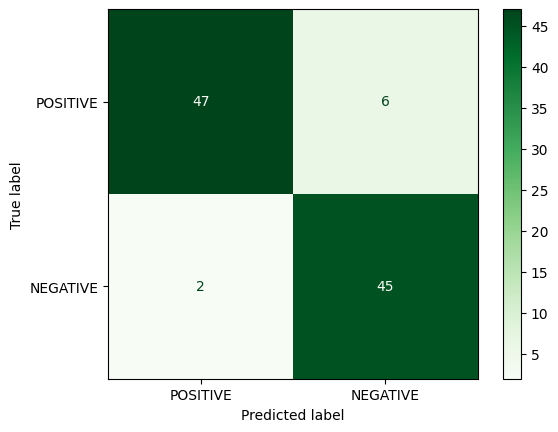

In [212]:
cm2=confusion_matrix(y_true, y_pred2, labels=["POSITIVE","NEGATIVE"])
ConfusionMatrixDisplay(cm2, display_labels=["POSITIVE", "NEGATIVE"]).plot(cmap="Greens")
plt.show()

In [171]:
print("Model 1 time:", round(elapsed, 2), "seconds")
print("Model 2 time:", round(elapsed2, 2), "seconds")

Model 1 time: 23.81 seconds
Model 2 time: 13.11 seconds


In [172]:
#try another model :
model3= pipeline("text-classification",model="cardiffnlp/twitter-xlm-roberta-base-sentiment")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [173]:
print(model3.model.config.id2label)

{0: 'negative', 1: 'neutral', 2: 'positive'}


In [174]:
print(model3("The food was delicious and the service was excellent."))
print(model3("The food was terrible and the service was very slow."))
print(model3("The food was amazing but the service was awful."))
print(model3("Okay."))

[{'label': 'positive', 'score': 0.9103062748908997}]
[{'label': 'negative', 'score': 0.9416850805282593}]
[{'label': 'negative', 'score': 0.9217671155929565}]
[{'label': 'neutral', 'score': 0.47840631008148193}]


In [176]:
# same steps for model 3
reviews=sent["review"].astype(str).tolist()
outputs3=[]
start=time.time()

for review in reviews:
    result=model3(review)[0]
    outputs3.append(result)

elapsed3=time.time()- start
print("Total time:", round(elapsed3, 2), "seconds")

out_df3=pd.DataFrame(outputs3)
sent["prediction3"]=out_df3["label"].str.upper()
sent["score3"]=out_df3["score"]

Total time: 14.96 seconds


In [177]:
sent[["review","prediction3", "score3", "true_label"]].head(10)

,review,prediction3,score3,true_label
0,Wow... Loved this place.,POSITIVE,0.946637,POSITIVE
1,Crust is not good.,NEGATIVE,0.943938,NEGATIVE
2,Not tasty and the texture was just nasty.,NEGATIVE,0.936408,NEGATIVE
3,Stopped by during the late May bank holiday of...,POSITIVE,0.902710,POSITIVE
4,The selection on the menu was great and so wer...,POSITIVE,0.852176,POSITIVE
5,Now I am getting angry and I want my damn pho.,NEGATIVE,0.917577,NEGATIVE
6,Honeslty it didn't taste THAT fresh.),NEGATIVE,0.787703,NEGATIVE
7,The potatoes were like rubber and you could te...,NEUTRAL,0.690742,NEGATIVE
8,The fries were great too.,POSITIVE,0.889846,POSITIVE
9,A great touch.,POSITIVE,0.943468,POSITIVE


In [178]:
y_pred3=sent["prediction3"]
print("Accuracy:", accuracy_score(y_true, y_pred3))
print(classification_report(y_true, y_pred3, digits=3, zero_division=0))

Accuracy: 0.9
              precision    recall  f1-score   support

    NEGATIVE      0.976     0.851     0.909        47
     NEUTRAL      0.000     0.000     0.000         0
    POSITIVE      0.926     0.943     0.935        53

    accuracy                          0.900       100
   macro avg      0.634     0.598     0.615       100
weighted avg      0.949     0.900     0.923       100



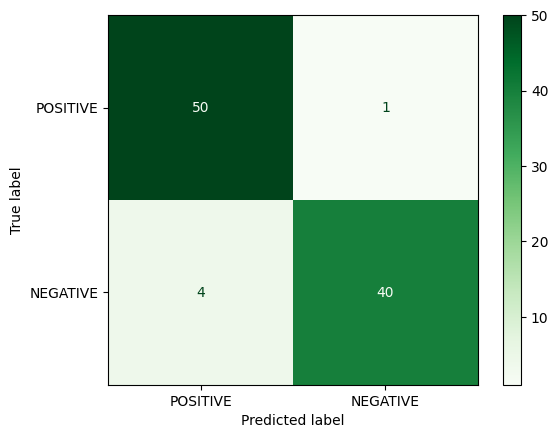

In [213]:
cm3=confusion_matrix(y_true, y_pred3, labels=["POSITIVE","NEGATIVE"])
ConfusionMatrixDisplay(cm3, display_labels=["POSITIVE", "NEGATIVE"]).plot(cmap="Greens")
plt.show()

In [179]:
## compare :
from sklearn.metrics import f1_score

#fliter it to 2 :pos, neg
print("Model 3 F1 ", f1_score(y_true, sent["prediction3"], labels=["POSITIVE", "NEGATIVE"], average="macro"))

Model 3 F1  0.9218351741716228


In [180]:
models = {
    "Model 1 (Yelp BERT)": ("prediction",  elapsed),
    "Model 2 (DistilBERT)": ("prediction2", elapsed2),
    "Model 3 (XLM-R)":      ("prediction3", elapsed3),
}

rows=[]
for name, (col, t) in models.items():
  # create table to compare :
    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_true, sent[col]), 3),
        "Macro F1 (POS/NEG)": round(f1_score(y_true, sent[col], labels=["POSITIVE", "NEGATIVE"], average="macro"), 3),
        "Errors": int((y_true != sent[col]).sum()),
        "Time (s)": round(t, 2),
    })

pd.DataFrame(rows)

,Model,Accuracy,Macro F1 (POS/NEG),Errors,Time (s)
0,Model 1 (Yelp BERT),0.93,0.929,7,23.81
1,Model 2 (DistilBERT),0.92,0.920,8,13.11
2,Model 3 (XLM-R),0.90,0.922,10,14.96


In [181]:
# see the diffrenent between model's errors:
e1=set(sent.index[y_true != sent["prediction"]])
e2=set(sent.index[y_true != sent["prediction2"]])
e3=set(sent.index[y_true != sent["prediction3"]])

print("Wrong in all 3:", sorted(e1 & e2 & e3))
print("Only M1:", sorted(e1-e2-e3))
print("Only M2:", sorted(e1-e2-e3))
print("Only M3:", sorted(e1-e2-e3))

Wrong in all 3: [51]
Only M1: [28, 56]
Only M2: [28, 56]
Only M3: [28, 56]


Model 1 (Yelp BERT) achieved the highest accuracy (93%), followed by Model 2 (DistilBERT) with 92%, and Model 3 (XLM-R) with 90%. The differences are small, and the test included only 100 reviews.

I recommend Model 1 because it had the highest accuracy and was trained on Yelp restaurant reviews, similar to my dataset.

Model 2 is a good alternative if speed and model size are more important. It was the fastest model (8.61s) and the smallest (67M parameters).

Model 3 had the lowest accuracy and sometimes predicted NEUTRAL instead of POSITIVE or NEGATIVE. Although it supports multiple languages, I did not test it on Arabic reviews, so more testing is needed before choosing it for Arabic.

In [183]:
#check:
all_errors= sorted(e1|e2|e3)
print(len(all_errors), "unique failure cases")
sent.loc[all_errors,["review", "true_label", "prediction", "prediction2", "prediction3"]]

18 unique failure cases


,review,true_label,prediction,prediction2,prediction3
7,The potatoes were like rubber and you could te...,NEGATIVE,NEGATIVE,NEGATIVE,NEUTRAL
13,"I tried the Cape Cod ravoli, chicken, with cra...",POSITIVE,POSITIVE,NEGATIVE,POSITIVE
26,#NAME?,NEGATIVE,NEGATIVE,NEGATIVE,NEUTRAL
28,Took an hour to get our food only 4 tables in ...,NEGATIVE,POSITIVE,NEGATIVE,NEGATIVE
31,This was like the final blow!,NEGATIVE,NEGATIVE,NEGATIVE,POSITIVE
32,I found this place by accident and I could not...,POSITIVE,NEGATIVE,NEGATIVE,POSITIVE
33,seems like a good quick place to grab a bite o...,NEGATIVE,POSITIVE,NEGATIVE,POSITIVE
35,The only redeeming quality of the restaurant w...,POSITIVE,POSITIVE,NEGATIVE,POSITIVE
40,The shrimp tender and moist.,POSITIVE,POSITIVE,POSITIVE,NEGATIVE
45,The only thing I did like was the prime rib an...,POSITIVE,POSITIVE,NEGATIVE,POSITIVE


Model 1 often misclassified indirect negative reviews as POSITIVE, sometimes with high confidence. Model 2 struggled with positive words in negative reviews. Model 3 had difficulty with short reviews and sometimes predicted NEUTRAL. Only one review (row 51) was misclassified by all three models.

In [184]:
##Does the Model Understand My Domain?

Yelp BERT was trained on restaurant reviews, so its training data is similar to my dataset. However, it sometimes struggled with indirect negative reviews and mixed feelings. The other models were trained on different types of data, which may have affected their results.

In [185]:
## Decide What to Do Next

I choose Yelp BERT because it achieved the highest accuracy 92% and the fewest errors is 7. I will use it as-is, but more restaurant reviews could help improve its performance.



## task b

In [186]:
from google.colab import files

uploaded = files.upload()

Saving bahrain_restaurant_reviews_balanced_35.csv to bahrain_restaurant_reviews_balanced_35 (1).csv


In [187]:
task2=pd.read_csv("bahrain_restaurant_reviews_balanced_35.csv")

In [188]:
# because i made my data sort by candidate labels
task2 = task2.sample(frac=1, random_state=42).reset_index(drop=True)

In [189]:
print(task2.shape)
print(task2.head())

(35, 9)
  review_id                  restaurant  \
0    BH_043          Juhaina Restaurant   
1    BH_032  Badawi Lebanese Restaurant   
2    BH_041            Brasserie Royale   
3    BH_018              Takht Jamsheed   
4    BH_034          Baharat Restaurant   

                                         review_text   true_label  \
0  Found this great place while walking the back ...     Location   
1                Prices are a bit on the higher end.        Price   
2  Have a nice pool and beach view with luxury Ro...   Atmosphere   
3                 The decorations were mind blowing.   Atmosphere   
4  Very nice restaurant with a clean and quiet en...  Cleanliness   

                         source_type  \
0         Tripadvisor review excerpt   
1  Wanderlog / Google review excerpt   
2  Wanderlog / Google review excerpt   
3         Tripadvisor review excerpt   
4         Tripadvisor review excerpt   

                                          source_url review_date  country  \


In [190]:
print(task2["true_label"].value_counts())

true_label
Location        5
Price           5
Atmosphere      5
Cleanliness     5
Service         5
Waiting Time    5
Food Quality    5
Name: count, dtype: int64


In [191]:
zero_shot= pipeline("zero-shot-classification", model="facebook/bart-large-mnli")

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

In [192]:
##labels :
candidate_labels=["Food Quality","Service","Price","Cleanliness","Atmosphere","Location","Waiting Time"]

In [193]:
#try one thing :
try1=task2["review_text"][0]
result= zero_shot(try1,candidate_labels)


print("Review:",try1)
print("Predicted label:",result["labels"][0])
print("Confidence:",result["scores"][0])

Review: Found this great place while walking the back streets of Manama. It’s near or in the souk.
Predicted label: Location
Confidence: 0.5748008489608765


In [194]:
#all the data :
predictions=[]
for review in task2["review_text"]:
    result=zero_shot(review, candidate_labels)
    predictions.append(result)



task2["predicted_label"]=[x["labels"][0] for x in predictions]
task2["confidence"]=[x["scores"][0] for x in predictions]

In [195]:
task2[["review_text","true_label","predicted_label","confidence"]].head(10)

,review_text,true_label,predicted_label,confidence
0,Found this great place while walking the back ...,Location,Location,0.574801
1,Prices are a bit on the higher end.,Price,Price,0.732329
2,Have a nice pool and beach view with luxury Ro...,Atmosphere,Location,0.418223
3,The decorations were mind blowing.,Atmosphere,Atmosphere,0.238158
4,Very nice restaurant with a clean and quiet en...,Cleanliness,Cleanliness,0.406695
5,Limited parking available.,Location,Location,0.648665
6,Very neat and clean.,Cleanliness,Cleanliness,0.867399
7,All for 1 BHD.,Price,Price,0.837238
8,Worst service and arrogant staff.,Service,Service,0.701229
9,The place is clean and has a separate families...,Cleanliness,Cleanliness,0.623191


In [196]:
# evaluate :
y_true=task2["true_label"]
y_pred=task2["predicted_label"]

print("Accuracy:",accuracy_score(y_true, y_pred))
print(classification_report(y_true, y_pred, digits=3))

Accuracy: 0.7714285714285715
              precision    recall  f1-score   support

  Atmosphere      1.000     0.200     0.333         5
 Cleanliness      0.833     1.000     0.909         5
Food Quality      0.714     1.000     0.833         5
    Location      0.714     1.000     0.833         5
       Price      1.000     1.000     1.000         5
     Service      0.500     0.600     0.545         5
Waiting Time      1.000     0.600     0.750         5

    accuracy                          0.771        35
   macro avg      0.823     0.771     0.744        35
weighted avg      0.823     0.771     0.744        35



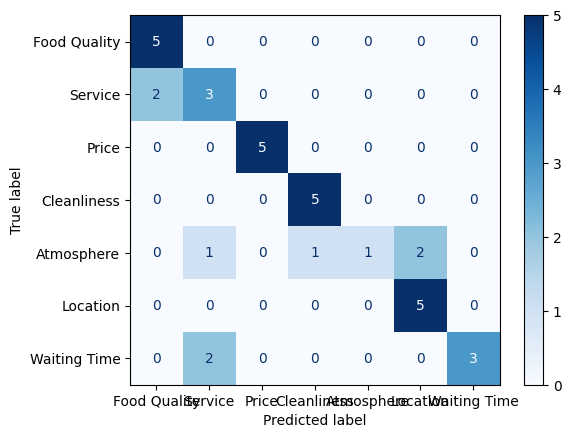

In [197]:
cm_zero=confusion_matrix(y_true, y_pred, labels=candidate_labels)
ConfusionMatrixDisplay(cm_zero,display_labels=candidate_labels).plot(cmap="Blues")
plt.show()

Accuracy, Precision, Recall, and F1-score were selected to evaluate the model's performance in classifying reviews into seven categories. These metrics measure overall accuracy and how well the model identifies each category.

In [199]:
#data Analysis:
error=task2[task2["true_label"] != task2["predicted_label"]]

In [200]:
error[["review_text","true_label","predicted_label","confidence"]]

,review_text,true_label,predicted_label,confidence
2,Have a nice pool and beach view with luxury Ro...,Atmosphere,Location,0.418223
10,Staff are friendly; food is good.,Service,Food Quality,0.518131
20,"Food service was inconsistent, with dishes arr...",Waiting Time,Service,0.569912
22,The only area that could be improved was the s...,Waiting Time,Service,0.796952
23,Beautiful internal design and arrangement.,Atmosphere,Cleanliness,0.241088
26,A quiet back street full of charm.,Atmosphere,Location,0.740908
29,"The food was good, but unfortunately my experi...",Service,Food Quality,0.391507
30,"Great service, excellent fare, relaxing music ...",Atmosphere,Service,0.559179


In [201]:
#The model made 8 classification errors out of 35 reviews. Most errors occurred because some reviews
#contained multiple topics or overlapping information.
#For example, reviews mentioning both service and food quality were sometimes classified incorrectly. The model also confused Atmosphere
#with Location and Cleanliness. These errors suggest that short reviews and reviews covering multiple aspects can make
# zero-shot classification more challenging.

### Error Analysis

**Error 1**
- **Input:** "Have a nice pool and beach view with luxury Royal decoration!"
- **Expected Output:** Atmosphere
- **Model Prediction:** Location
- **Confidence:** 0.418
- **Explanation:** The model focused on the pool and beach view, interpreting the review as related to location rather than atmosphere.

**Error 2**
- **Input:** "Staff are friendly; food is good."
- **Expected Output:** Service
- **Model Prediction:** Food Quality
- **Confidence:** 0.518
- **Explanation:** The review mentions both staff and food, but the model focused more on food quality.

**Error 3**
- **Input:** "Food service was inconsistent, with dishes arriving..."
- **Expected Output:** Waiting Time
- **Model Prediction:** Service
- **Confidence:** 0.570
- **Explanation:** The model interpreted the phrase "food service" as general service rather than focusing on the time taken for dishes to arrive.

**Error 4**
- **Input:** "The only area that could be improved was the service..."
- **Expected Output:** Waiting Time
- **Model Prediction:** Service
- **Confidence:** 0.797
- **Explanation:** The word "service" strongly suggests the Service category, making it difficult for the model to identify the intended waiting-time aspect.

**Error 5**
- **Input:** "Beautiful internal design and arrangement."
- **Expected Output:** Atmosphere
- **Model Prediction:** Cleanliness
- **Confidence:** 0.241
- **Explanation:** The model confused the restaurant's interior design with cleanliness.

**Error 6**
- **Input:** "A quiet back street full of charm."
- **Expected Output:** Atmosphere
- **Model Prediction:** Location
- **Confidence:** 0.741
- **Explanation:** The model focused on the reference to the street rather than the description of the atmosphere.

**Error 7**
- **Input:** "The food was good, but unfortunately my experience..."
- **Expected Output:** Service
- **Model Prediction:** Food Quality
- **Confidence:** 0.392
- **Explanation:** The model focused on the mention of food instead of identifying the main issue related to service.

**Error 8**
- **Input:** "Great service, excellent fare, relaxing music..."
- **Expected Output:** Atmosphere
- **Model Prediction:** Service
- **Confidence:** 0.559
- **Explanation:** The review mentions several aspects, and the model focused on service instead of the overall atmosphere.

In [202]:
##Another model :
zero_shot2=pipeline("zero-shot-classification", model="MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

In [203]:
#try one thing :
try1=task2["review_text"][0]
result= zero_shot2(try1,candidate_labels)


print("Review:",try1)
print("Predicted label:",result["labels"][0])
print("Confidence:",result["scores"][0])

Review: Found this great place while walking the back streets of Manama. It’s near or in the souk.
Predicted label: Location
Confidence: 0.715364396572113


In [204]:
start_time=time.time()
predictions_2=[]


for review in task2["review_text"]:
    result=zero_shot2(review, candidate_labels)
    predictions_2.append(result)

time_2=time.time()-start_time

task2["predicted_label2"]=[x["labels"][0] for x in predictions_2]
task2["confidence2"]=[x["scores"][0] for x in predictions_2]

print("Inference Time:", round(time_2, 2), "seconds")

Inference Time: 4.75 seconds


In [205]:
y_pred_2=task2["predicted_label2"]


print("Accuracy:", accuracy_score(y_true, y_pred_2))
print(classification_report(y_true, y_pred_2, digits=3))

Accuracy: 0.6571428571428571
              precision    recall  f1-score   support

  Atmosphere      0.000     0.000     0.000         5
 Cleanliness      0.833     1.000     0.909         5
Food Quality      0.571     0.800     0.667         5
    Location      0.500     1.000     0.667         5
       Price      1.000     0.800     0.889         5
     Service      0.500     0.600     0.545         5
Waiting Time      1.000     0.400     0.571         5

    accuracy                          0.657        35
   macro avg      0.629     0.657     0.607        35
weighted avg      0.629     0.657     0.607        35



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [206]:
error2=task2[task2["true_label"] != task2["predicted_label2"]]
error2[["review_text","true_label","predicted_label2","confidence2"]]

,review_text,true_label,predicted_label2,confidence2
2,Have a nice pool and beach view with luxury Ro...,Atmosphere,Location,0.397414
3,The decorations were mind blowing.,Atmosphere,Location,0.263226
7,All for 1 BHD.,Price,Location,0.393729
10,Staff are friendly; food is good.,Service,Food Quality,0.565391
11,More than 15 minutes for someone to take the o...,Waiting Time,Food Quality,0.307998
20,"Food service was inconsistent, with dishes arr...",Waiting Time,Service,0.387043
21,The food was extremely bad and extremely salty.,Food Quality,Cleanliness,0.207659
22,The only area that could be improved was the s...,Waiting Time,Service,0.468164
23,Beautiful internal design and arrangement.,Atmosphere,Location,0.443187
26,A quiet back street full of charm.,Atmosphere,Location,0.512311


MiniLM made 12 classification errors out of 35 reviews. It often confused Atmosphere with Location and Service with Waiting Time. It also struggled with reviews that mentioned more than one topic, such as food quality and service.

In [207]:
# compare :

BART model achieved better classification performance 77.14% accuracy and a 74.4% F1-score, compared to MiniLM's model is 65.71% accuracy and 60.7% F1-score.
However, MiniLM is smaller, faster, and supports more languages. Since this application focuses on English restaurant reviews in Bahrain, classification performance is more important than multilingual support.
Therefore, **BART** is recommended as the more suitable model for this application, despite its larger size and slower inference speed.

In [208]:
# Does the Model Understand My Domain?

Both models were trained on general text, not specifically on restaurant reviews.

They may struggle with Bahrain-specific expressions and reviews that mention multiple topics, such as food quality and service.
This could explain some of their classification errors.

In [209]:
## Decide What to Do Next :

Use the pretrained BART model as-is because it achieved better results than MiniLM. However, testing more reviews and improving the candidate labels may help improve its performance